# Heads-Up Limit Texas Hold'em: Strategy & Game Theory Engine
## Milestone 1: Stateful Engine & Hand Evaluator

This milestone builds the core of the project:

1. **`Card` & `Deck`**: card representation, ordering, shuffling and dealing.
2. **`HandEvaluator`**: picks the best 5-card hand out of 7 cards, ranks it (High Card up to Royal Flush) and breaks ties with kickers.
3. **`Player`, agents & `GameEngine`**: a turn-based heads-up engine that can run on its own (AI vs. AI) or with a human seat. Betting is **No-Limit** by default (choose your size, min-raise rules, all-in); pass `betting="limit"` for Fixed-Limit.
4. **Verification & visualization**: unit tests, a full hand to showdown, an autonomous session and a horizontal showdown comparison chart.
5. **Play it yourself**: run the last cell for a clickable table against the bot. The bot's cards stay face down unless the hand reaches showdown.

## Python Concepts Used in This Notebook

A quick guide to the Python tools in this project that go beyond the basics. Each entry says **what it does**, **where we use it**, and **what the plain-Python version would look like**.

---

### 1. `@dataclass`: classes without the boilerplate
*Used in:* `Card` (Cell 2), `HandRank` (Cell 3), `TableState` (Cell 5)

Writing `@dataclass` above a class makes Python generate `__init__`, `__repr__` (how it prints) and `__eq__` (`==`) from the list of fields.

```python
@dataclass(frozen=True, order=True)
class Card:
    rank: int   # 2..14
    suit: str   # 'c', 'd', 'h', 's'
```

| Option | Meaning | Why we need it |
|---|---|---|
| `frozen=True` | The object can't be changed after it's created | Cards can go in a `set` (used to catch duplicate cards), and bots can't tamper with the `TableState` they're given |
| `order=True` | Generates `<`, `>` etc., comparing fields in order (rank, then suit) | `sorted(cards)` works |
| `eq=False` | "Don't generate `==`, we write our own" | Two hands are equal if they're equally strong, even with different cards |

**Plain version:** a normal class with `__init__`, `__eq__`, `__lt__`, `__hash__` and `__repr__` written out by hand. It works the same but is about 15 lines longer.

---

### 2. `IntEnum`: named numbers
*Used in:* `HandCategory` (Cell 3)

`HandCategory.FLUSH` **is** the number `5`, so categories compare like numbers (`FLUSH > STRAIGHT`), but they print as names and can't be mistyped.

**Plain version:** constants such as `HIGH_CARD, ONE_PAIR, ... = 0, 1, ...` plus a list of names for printing.

---

### 3. `@total_ordering`: write two comparisons, get all of them
*Used in:* `HandRank` (Cell 3)

We write `__eq__` and `__lt__`; it fills in `<=`, `>` and `>=`. That lets us use `max()` to pick the best hand and `<` in the tests.

**Plain version:** write all four comparison methods yourself.

---

### 4. `@property`, `@staticmethod`, `@classmethod`
*Used in:* several cells

| Decorator | What it does | Example in our code |
|---|---|---|
| `@property` | A method you read like a variable (no parentheses) | `engine.pot` is recalculated from the players' bets every time, so it can never be out of date |
| `@staticmethod` | A function stored inside a class that doesn't use `self` | `HandEvaluator.evaluate_five(cards)` |
| `@classmethod` | Receives the class (`cls`) instead of an object, often used to build new objects | `Card.from_str("Ah")` |

**Plain version:** use `def pot(self)` and call `engine.pot()`, or write ordinary functions outside the class.

---

### 5. `Counter`: counting things
*Used in:* the hand evaluator (Cell 3) and session stats (Cell 9)

```python
Counter([13, 13, 7, 7, 14])   # -> {13: 2, 7: 2, 14: 1}  (two pair: Kings and Sevens)
```

**Plain version:**
```python
counts = {}
for rank in ranks:
    counts[rank] = counts.get(rank, 0) + 1
```

---

### 6. `itertools.combinations`: every possible group
*Used in:* `HandEvaluator.best_hand` (Cell 3)

`combinations(seven_cards, 5)` produces all **21** five-card hands you can make from 7 cards. We score each one and keep the best.

**Plain version:** five nested `for` loops. That's long and error-prone, so we keep `combinations`.

---

### 7. Generators (`yield`, `yield from`, `.send()`): pausing a function ⭐
*Used in:* `GameEngine.hand_steps` and `_betting_round` (Cell 6)

**The problem:** with clickable buttons, Python can't wait for a click inside a loop the way `input()` waits for typing. The cell finishes and the click arrives later. So the engine needs to **pause in the middle of a hand** and resume later from exactly the same spot.

**How it works:** a function containing `yield` pauses each time it reaches `yield`, hands a value out, and waits. `.send(x)` wakes it up, and `x` becomes the result of the `yield`.

```python
def tiny_hand():
    answer = yield "Your turn: check or bet?"   # pause #1
    print("You chose", answer)
    yield "Bot's turn"                          # pause #2

g = tiny_hand()
print(g.send(None))    # starts it    -> Your turn: check or bet?
print(g.send("bet"))   # resumes it   -> You chose bet / Bot's turn
```

In the engine, `action = yield player, state` means *"here's who must act and what they can see; send me their action."*
- `yield from self._betting_round(street)` lets the betting round pause the whole hand.
- When the hand finishes, Python raises `StopIteration`, which carries the hand's record in `.value`.
- The table UI (Cell 10) sends your button clicks in. `play_hand()` sends the bots' decisions in.

**Plain version:** either play by text only with `input()`, or rewrite the engine as a "state machine" that stores whose turn it is, the current bet, etc., and moves one step per action. That's more code and easier to get wrong, so we keep generators.

---

### 8. `ipywidgets`: clickable controls in the notebook
*Used in:* `PokerTableUI` (Cell 10)

| Widget | Job |
|---|---|
| `Button` | Fold / Check / Call / Bet / Raise / All-in / Deal next hand |
| `IntSlider` | Choosing the raise size |
| `HTML` | Drawing the table and cards |
| `Output` | Holding the showdown chart |
| `HBox` / `VBox` | Placing widgets side by side / stacked |

`button.on_click(func)` runs `func` when the button is clicked. `slider.observe(func, names="value")` runs `func` when the slider moves.

---

### 9. Smaller syntax you'll see

| Code | Meaning | Plain version |
|---|---|---|
| `for ... : break` followed by `else:` | The `else` runs only if the loop finished **without** `break` (here: nobody folded, so go to showdown) | A flag variable such as `folded = False` |
| `next((a for a in items if ...), None)` | Find the first matching item, or `None` | A `for` loop with `break` |
| `lambda _: self._act("fold")` | A tiny unnamed one-line function, used for button clicks | `def on_fold(button): ...` |
| `lambda _, f=fraction: ...` | `f=fraction` locks in this loop pass's value; without it every preset button would use the last one | A separate `def` per button |
| `isinstance(action, tuple)` | Checks whether a bot answered `("raise", 24)` or just `"call"` | (already basic) |
| `share, odd_chip = divmod(pot, 2)` | Quotient and remainder at once | `pot // 2` and `pot % 2` |
| `random.Random(seed)` | A private random generator: same seed means the same shuffle every run | `random.seed(42)` (affects all code) |
| `html.escape(name)` | Makes text safe to put inside HTML | (could skip it, since we choose the names) |
| `assert condition, "message"` | Stops with an error if the condition is false; this is how our tests work | `if not condition: raise AssertionError("message")` |

In [1]:
# Cell 1: Imports & global configuration
import random
from collections import Counter
from dataclasses import dataclass
from enum import IntEnum
from functools import total_ordering
from itertools import combinations

import matplotlib.pyplot as plt

RANKS = "23456789TJQKA"
RANK_VALUES = {char: value for value, char in enumerate(RANKS, start=2)}
RANK_NAMES = {
    2: "Two",
    3: "Three",
    4: "Four",
    5: "Five",
    6: "Six",
    7: "Seven",
    8: "Eight",
    9: "Nine",
    10: "Ten",
    11: "Jack",
    12: "Queen",
    13: "King",
    14: "Ace",
}
RANK_PLURALS = {value: name + "s" for value, name in RANK_NAMES.items()}
RANK_PLURALS[6] = "Sixes"

SUITS = "cdhs"  # clubs < diamonds < hearts < spades (used only to sort)
SUIT_SYMBOLS = {"c": "♣", "d": "♦", "h": "♥", "s": "♠"}

STREETS = ("Pre-Flop", "Flop", "Turn", "River")
BOARD_CARDS_PER_STREET = {"Pre-Flop": 0, "Flop": 3, "Turn": 1, "River": 1}

In [2]:
# Cell 2: Card & Deck classes
@dataclass(frozen=True, order=True)
class Card:
    """An immutable playing card. Cards sort by rank first, then by suit."""

    rank: int  # 2..14 (14 = Ace)
    suit: str  # one of 'c', 'd', 'h', 's'

    def __post_init__(self):
        if self.rank not in RANK_NAMES:
            raise ValueError(f"Invalid rank: {self.rank}")
        if self.suit not in SUITS:
            raise ValueError(f"Invalid suit: {self.suit}")

    @classmethod
    def from_str(cls, text):
        """Build a card from short notation, e.g. 'Ah', 'Td', '7c'."""
        return cls(RANK_VALUES[text[0].upper()], text[1].lower())

    @property
    def rank_char(self):
        return RANKS[self.rank - 2]

    def __str__(self):
        return f"{self.rank_char}{SUIT_SYMBOLS[self.suit]}"

    def __repr__(self):
        return f"Card('{self.rank_char}{self.suit}')"


def parse_cards(text):
    """Parse a space-separated card string: parse_cards('Ah Kd 7c')."""
    return [Card.from_str(token) for token in text.split()]


def format_cards(cards):
    return " ".join(str(card) for card in cards)


class Deck:
    """A standard 52-card deck with its own random generator (seedable)."""

    def __init__(self, rng=None):
        self.rng = rng or random.Random()
        self.cards = []
        self.reset()

    def reset(self):
        self.cards = [Card(rank, suit) for suit in SUITS for rank in RANK_NAMES]

    def shuffle(self):
        self.rng.shuffle(self.cards)

    def deal(self, count=1):
        if count > len(self.cards):
            raise ValueError("Not enough cards left in the deck.")
        return [self.cards.pop() for _ in range(count)]

    def burn(self):
        self.deal(1)

    def __len__(self):
        return len(self.cards)


deck = Deck(random.Random(42))
deck.shuffle()
print("Sorted sample:", format_cards(sorted(deck.deal(5), reverse=True)))
print("Cards left:", len(deck))

Sorted sample: T♠ 9♣ 6♦ 3♠ 3♣
Cards left: 47


In [3]:
# Cell 3: Hand evaluator (best 5 of up to 7 cards)
class HandCategory(IntEnum):
    HIGH_CARD = 0
    ONE_PAIR = 1
    TWO_PAIR = 2
    THREE_OF_A_KIND = 3
    STRAIGHT = 4
    FLUSH = 5
    FULL_HOUSE = 6
    FOUR_OF_A_KIND = 7
    STRAIGHT_FLUSH = 8
    ROYAL_FLUSH = 9

    @property
    def label(self):
        return self.name.replace("_", " ").title().replace(" Of A ", " of a ")


@total_ordering
@dataclass(frozen=True, eq=False)
class HandRank:
    """The value of a 5-card hand.

    Hands compare on (category, tiebreak). `tiebreak` lists the ranks that
    matter in order of importance, e.g. Two Pair K-K-7-7-A -> (13, 7, 14).
    """

    category: HandCategory
    tiebreak: tuple
    cards: tuple  # the five cards, ordered for display

    @property
    def key(self):
        return (self.category, self.tiebreak)

    def __eq__(self, other):
        return self.key == other.key

    def __lt__(self, other):
        return self.key < other.key

    @property
    def strength(self):
        """A continuous score in [0, 10): category + kicker fraction.

        Every tiebreak rank is < 15, so the base-15 fraction preserves the
        exact lexicographic ordering of the hands.
        """
        fraction = sum(rank / 15 ** (i + 1) for i, rank in enumerate(self.tiebreak))
        return self.category + fraction

    def describe(self):
        cat, t = self.category, self.tiebreak
        name, plural = RANK_NAMES, RANK_PLURALS
        kickers = lambda ranks: " ".join(RANKS[r - 2] for r in ranks)
        if cat == HandCategory.ROYAL_FLUSH:
            return "Royal Flush"
        if cat == HandCategory.STRAIGHT_FLUSH:
            return f"Straight Flush, {name[t[0]]} high"
        if cat == HandCategory.FOUR_OF_A_KIND:
            return f"Four {plural[t[0]]}, kicker {kickers(t[1:])}"
        if cat == HandCategory.FULL_HOUSE:
            return f"Full House, {plural[t[0]]} full of {plural[t[1]]}"
        if cat == HandCategory.FLUSH:
            return f"Flush, {kickers(t)}"
        if cat == HandCategory.STRAIGHT:
            return f"Straight, {name[t[0]]} high"
        if cat == HandCategory.THREE_OF_A_KIND:
            return f"Three {plural[t[0]]}, kickers {kickers(t[1:])}"
        if cat == HandCategory.TWO_PAIR:
            return f"Two Pair, {plural[t[0]]} & {plural[t[1]]}, kicker {kickers(t[2:])}"
        if cat == HandCategory.ONE_PAIR:
            return f"Pair of {plural[t[0]]}, kickers {kickers(t[1:])}"
        return f"High Card, {kickers(t)}"

    def __repr__(self):
        return f"<{self.describe()} | {format_cards(self.cards)}>"


class HandEvaluator:
    """Stateless poker hand evaluation utilities."""

    @staticmethod
    def evaluate_five(five):
        if len(five) != 5:
            raise ValueError("evaluate_five needs exactly 5 cards.")
        ranks = sorted((card.rank for card in five), reverse=True)
        counts = Counter(ranks)
        # Group ranks by (multiplicity, rank): quads before trips before pairs.
        groups = sorted(
            counts.items(), key=lambda item: (item[1], item[0]), reverse=True
        )
        grouped_ranks = tuple(rank for rank, _ in groups)
        shape = [count for _, count in groups]

        is_flush = len({card.suit for card in five}) == 1
        straight_high = None
        if len(counts) == 5:
            if ranks[0] - ranks[4] == 4:
                straight_high = ranks[0]
            elif ranks == [14, 5, 4, 3, 2]:  # the wheel: A-2-3-4-5
                straight_high = 5

        # Display order: biggest group first; in a wheel the Ace goes last.
        def display_key(card):
            rank = 1 if straight_high == 5 and card.rank == 14 else card.rank
            return (counts[card.rank], rank, card.suit)

        ordered = tuple(sorted(five, key=display_key, reverse=True))

        if straight_high and is_flush:
            category = (
                HandCategory.ROYAL_FLUSH
                if straight_high == 14
                else HandCategory.STRAIGHT_FLUSH
            )
            return HandRank(category, (straight_high,), ordered)
        if shape == [4, 1]:
            return HandRank(HandCategory.FOUR_OF_A_KIND, grouped_ranks, ordered)
        if shape == [3, 2]:
            return HandRank(HandCategory.FULL_HOUSE, grouped_ranks, ordered)
        if is_flush:
            return HandRank(HandCategory.FLUSH, tuple(ranks), ordered)
        if straight_high:
            return HandRank(HandCategory.STRAIGHT, (straight_high,), ordered)
        if shape == [3, 1, 1]:
            return HandRank(HandCategory.THREE_OF_A_KIND, grouped_ranks, ordered)
        if shape == [2, 2, 1]:
            return HandRank(HandCategory.TWO_PAIR, grouped_ranks, ordered)
        if shape == [2, 1, 1, 1]:
            return HandRank(HandCategory.ONE_PAIR, grouped_ranks, ordered)
        return HandRank(HandCategory.HIGH_CARD, tuple(ranks), ordered)

    @classmethod
    def best_hand(cls, hole_cards, board):
        """Best 5-card HandRank from 2 hole cards + 3..5 board cards."""
        cards = list(hole_cards) + list(board)
        if not 5 <= len(cards) <= 7:
            raise ValueError(f"Need 5-7 cards to evaluate, got {len(cards)}.")
        if len(set(cards)) != len(cards):
            raise ValueError("Duplicate cards detected.")
        return max(cls.evaluate_five(combo) for combo in combinations(cards, 5))

    @classmethod
    def showdown(cls, hands, board):
        """Evaluate {name: hole_cards}; return (winner_names, {name: HandRank})."""
        results = {name: cls.best_hand(hole, board) for name, hole in hands.items()}
        best = max(results.values())
        winners = [name for name, rank in results.items() if rank == best]
        return winners, results

In [4]:
# Cell 4: Evaluator unit testing
def check(hole, board, expected_category):
    rank = HandEvaluator.best_hand(parse_cards(hole), parse_cards(board))
    assert rank.category == expected_category, (hole, board, rank)
    return rank


royal = check("Ah Kh", "Qh Jh Th 2c 3d", HandCategory.ROYAL_FLUSH)
steel_wheel = check("Ac 2c", "3c 4c 5c Kd Kh", HandCategory.STRAIGHT_FLUSH)
quads = check("9s 9d", "9h 9c Ks 2d 3h", HandCategory.FOUR_OF_A_KIND)
boat = check("Ks Kd", "Kh 7c 7d 2s 3h", HandCategory.FULL_HOUSE)
flush = check("Ad 3d", "Kd 8d 2d Qs Js", HandCategory.FLUSH)
wheel = check("As 2d", "3c 4h 5s Kd Qh", HandCategory.STRAIGHT)
six_high = check("6s 2d", "3c 4h 5s Kd Qh", HandCategory.STRAIGHT)
trips = check("7s 7d", "7h Ac Ks 2d 4h", HandCategory.THREE_OF_A_KIND)
two_pair = check("Ks 7d", "Kh 7c Ad 2s 3h", HandCategory.TWO_PAIR)
pair = check("Qs Qd", "Ah 9c 5d 3s 2h", HandCategory.ONE_PAIR)
high = check("As Jd", "9h 7c 5d 3s 2h", HandCategory.HIGH_CARD)

# Category ordering and special cases.
ladder = [high, pair, two_pair, trips, six_high, flush, boat, quads, steel_wheel, royal]
assert all(a < b for a, b in zip(ladder, ladder[1:]))
assert wheel < six_high, "The wheel (A-5) is the lowest straight."
assert wheel.cards[-1].rank == 14, "The Ace is displayed last in a wheel."

# Best 5 of 7: a 6th straight card upgrades a straight.
assert check("6d 7d", "2s 3h 4c 5s Kd", HandCategory.STRAIGHT).tiebreak == (7,)

# Kicker resolution: same pair, better kicker wins.
board = "Kh 8c 5d 3s 2h"
winners, _ = HandEvaluator.showdown(
    {"A": parse_cards("Ks Qd"), "B": parse_cards("Kd Jc")}, parse_cards(board)
)
assert winners == ["A"], "Queen kicker beats Jack kicker."

# Two pair: the 5th card kicker decides.
winners, _ = HandEvaluator.showdown(
    {"A": parse_cards("As 4d"), "B": parse_cards("Qd 4c")},
    parse_cards("Kh Kc 9d 9s 2h"),
)
assert winners == ["A"]

# Board plays for both players -> split pot.
winners, _ = HandEvaluator.showdown(
    {"A": parse_cards("2c 3d"), "B": parse_cards("2d 3c")},
    parse_cards("As Ks Qs Js Ts"),
)
assert winners == ["A", "B"]

# Full houses compare trips first, then the pair.
assert check("Ks Kd", "Kh 2c 2d 9s 8h", HandCategory.FULL_HOUSE) > check(
    "Qs Qd", "Qh Ac Ad 9s 8h", HandCategory.FULL_HOUSE
)

# Flush vs flush is decided card by card.
assert check("Ad 2d", "Kd 8d 4d Qs Js", HandCategory.FLUSH) > check(
    "Ad 3d", "Qd 8d 4d Qs Js", HandCategory.FLUSH
)

for rank in reversed(ladder):
    print(f"{rank.category.label:<16} {format_cards(rank.cards):<16} {rank.describe()}")
print("\nAll evaluator tests passed.")

Royal Flush      A♥ K♥ Q♥ J♥ T♥   Royal Flush
Straight Flush   5♣ 4♣ 3♣ 2♣ A♣   Straight Flush, Five high
Four of a Kind   9♠ 9♥ 9♦ 9♣ K♠   Four Nines, kicker K
Full House       K♠ K♥ K♦ 7♦ 7♣   Full House, Kings full of Sevens
Flush            A♦ K♦ 8♦ 3♦ 2♦   Flush, A K 8 3 2
Straight         6♠ 5♠ 4♥ 3♣ 2♦   Straight, Six high
Three of a Kind  7♠ 7♥ 7♦ A♣ K♠   Three Sevens, kickers A K
Two Pair         K♠ K♥ 7♦ 7♣ A♦   Two Pair, Kings & Sevens, kicker A
One Pair         Q♠ Q♦ A♥ 9♣ 5♦   Pair of Queens, kickers A 9 5
High Card        A♠ J♦ 9♥ 7♣ 5♦   High Card, A J 9 7 5

All evaluator tests passed.


In [5]:
# Cell 5: Player, table state & agents
@dataclass(frozen=True)
class TableState:
    """A snapshot of everything an agent is allowed to see when acting.

    Bet and raise sizes are "raise to" amounts: the player's total bet on
    this street after the action, as in standard hold'em.
    """

    street: str
    betting: str  # "no-limit" or "limit"
    board: tuple
    hole_cards: tuple
    pot: int
    to_call: int
    current_bet: int  # the highest bet on this street so far
    street_bet: int  # what this player already put in on this street
    min_raise_to: int  # smallest legal bet/raise
    max_raise_to: int  # largest legal bet/raise (all-in in no-limit)
    bets_this_street: int
    chips: int
    opponent_chips: int
    legal_actions: tuple
    action_history: tuple

    def raise_to_for_pot_fraction(self, fraction):
        """Raise-to amount for a bet worth `fraction` of the pot (counting
        the call), clamped to the legal range. 1.0 = a pot-sized raise."""
        target = self.current_bet + round(fraction * (self.pot + self.to_call))
        return max(self.min_raise_to, min(self.max_raise_to, target))


class Player:
    """A seat at the table: chip stack, hole cards and bets this hand."""

    def __init__(self, name, chips, agent):
        self.name = name
        self.chips = chips
        self.agent = agent
        self.reset_for_hand()

    def reset_for_hand(self):
        self.hole_cards = []
        self.street_bet = 0  # chips put in on the current street
        self.total_bet = 0  # chips put in during the whole hand
        self.folded = False

    def commit(self, amount):
        """Move chips from the stack into the pot (capped at the stack)."""
        amount = min(amount, self.chips)
        self.chips -= amount
        self.street_bet += amount
        self.total_bet += amount
        return amount

    @property
    def is_all_in(self):
        return self.chips == 0 and not self.folded

    def __repr__(self):
        return f"Player({self.name!r}, chips={self.chips}, agent={self.agent.name})"


class Agent:
    """Base class: an agent maps a TableState to one of its legal actions.

    `decide` returns "fold", "check", "call", "all-in", or a sized bet as
    ("bet", raise_to) / ("raise", raise_to). A bare "bet" or "raise" means
    the minimum legal size.
    """

    name = "Agent"
    interactive = False  # True for seats controlled by a person

    def decide(self, state):
        raise NotImplementedError


class PassiveAgent(Agent):
    """Always checks or calls: guarantees the hand reaches showdown."""

    name = "Passive"

    def decide(self, state):
        return "check" if "check" in state.legal_actions else "call"


class ScriptedAgent(Agent):
    """Plays a fixed list of actions and remembers every state it saw (tests)."""

    name = "Scripted"

    def __init__(self, actions):
        self.actions = list(actions)
        self.seen = []

    def decide(self, state):
        self.seen.append(state)
        return self.actions.pop(0)


class RandomAgent(Agent):
    """Dummy agent: picks a legal action at random (weighted) and, in
    no-limit, a random size from min-raise, 1/2, 3/4 or a full pot."""

    name = "Random"
    DEFAULT_WEIGHTS = {
        "fold": 1,
        "check": 4,
        "call": 4,
        "bet": 2,
        "raise": 2,
        "all-in": 0.2,
    }
    POT_FRACTIONS = (0.5, 0.75, 1.0)

    def __init__(self, weights=None, rng=None):
        self.weights = weights or self.DEFAULT_WEIGHTS
        self.rng = rng or random.Random()

    def decide(self, state):
        actions = list(state.legal_actions)
        weights = [self.weights.get(action, 1) for action in actions]
        action = self.rng.choices(actions, weights=weights, k=1)[0]
        if action in ("bet", "raise") and state.betting == "no-limit":
            sizes = [state.min_raise_to] + [
                state.raise_to_for_pot_fraction(f) for f in self.POT_FRACTIONS
            ]
            return action, self.rng.choice(sizes)
        return action


class HumanAgent(Agent):
    """Interactive seat. The table UI (Cell 10) supplies its actions with
    buttons; `decide` is a plain-text input() fallback for play_hand().
    Text commands: f, x, c, a (all-in), or "b 20" / "r 20" to bet/raise to 20.
    """

    name = "Human"
    interactive = True
    SHORTCUTS = {
        "f": "fold",
        "x": "check",
        "c": "call",
        "b": "bet",
        "r": "raise",
        "a": "all-in",
    }

    def decide(self, state):
        print(f"\n--- {state.street} | Board: {format_cards(state.board) or '-'}")
        print(
            f"Your cards: {format_cards(state.hole_cards)} | Chips: {state.chips}"
            f" | Pot: {state.pot} | To call: {state.to_call}"
            f" | Bet/raise to: {state.min_raise_to}-{state.max_raise_to}"
        )
        options = "/".join(state.legal_actions)
        while True:
            tokens = input(f"Action ({options}): ").strip().lower().split()
            if not tokens:
                continue
            choice = self.SHORTCUTS.get(tokens[0], tokens[0])
            if choice not in state.legal_actions:
                print(f"'{choice}' is not legal here. Choose from: {options}")
            elif choice in ("bet", "raise") and len(tokens) > 1:
                amount = int(tokens[1])
                if state.min_raise_to <= amount <= state.max_raise_to:
                    return choice, amount
                print(f"Size must be {state.min_raise_to}-{state.max_raise_to}.")
            else:
                return choice

In [6]:
# Cell 6: Stateful heads-up GameEngine (No-Limit or Fixed-Limit)
class GameEngine:
    """Runs heads-up Texas Hold'em hands between two players.

    Heads-up rules: the button posts the small blind and acts first
    pre-flop; the big blind acts first on the flop, turn and river.

    betting="no-limit" (default): players choose their size. The minimum
    bet is the big blind, a raise must be at least as big as the previous
    bet or raise on that street, there is no cap on raises, and a player
    may go all-in at any time. An all-in for less than a full raise is
    allowed. Any part of a bet the opponent can't match is returned.

    betting="limit": fixed sizes - the small bet (= big blind) pre-flop and
    on the flop, the big bet (= 2x big blind) on the turn and river, capped
    at `bet_cap` bets per street (a bet plus three raises).

    `hand_steps()` is a generator that pauses at every decision, which lets
    a button-driven UI feed in a human's actions. `play_hand()` drives the
    same generator by asking each seat's agent.

    When a human sits at the table, the bot's hole cards are kept out of
    every log; they are only shown if the hand reaches showdown.
    """

    BETTING_STRUCTURES = ("no-limit", "limit")

    def __init__(
        self,
        player_one,
        player_two,
        small_blind=1,
        big_blind=2,
        betting="no-limit",
        bet_cap=4,
        seed=None,
        verbose=True,
    ):
        if betting not in self.BETTING_STRUCTURES:
            raise ValueError(f"betting must be one of {self.BETTING_STRUCTURES}")
        self.betting = betting
        self.players = [player_one, player_two]
        self.small_blind = small_blind
        self.big_blind = big_blind
        self.small_bet = big_blind
        self.big_bet = 2 * big_blind
        self.bet_cap = bet_cap
        self.rng = random.Random(seed)
        self.deck = Deck(self.rng)
        self.verbose = verbose
        self.button = 0  # index of the player on the button
        self.hand_number = 0
        self.street = None
        self.board = []
        self.action_log = []
        self.hand_log = []  # (owner, message) lines for the current hand
        self.history = []  # one record (dict) per completed hand
        # With no human seated, it is a spectator simulation: show everything.
        self.reveal_all = not any(p.agent.interactive for p in self.players)

    # ----- helpers ---------------------------------------------------------
    def can_see(self, owner):
        """Whether a log line that is private to `owner` may be shown."""
        if owner is None or self.reveal_all:
            return True
        return any(p.name == owner and p.agent.interactive for p in self.players)

    def log(self, message, owner=None):
        """Record a log line; `owner` marks it private to that player."""
        self.hand_log.append((owner, message))
        if self.verbose and self.can_see(owner):
            print(message)

    @property
    def pot(self):
        return sum(player.total_bet for player in self.players)

    def total_chips(self):
        return sum(player.chips for player in self.players) + self.pot

    def _live_players(self):
        return [player for player in self.players if not player.folded]

    def _bet_size(self, street):
        return self.small_bet if street in ("Pre-Flop", "Flop") else self.big_bet

    # ----- hand flow -------------------------------------------------------
    def play_hand(self):
        """Play one full hand, asking each seat's agent for its decisions."""
        steps = self.hand_steps()
        action = None
        while True:
            try:
                player, state = steps.send(action)
            except StopIteration as finished:
                return finished.value  # the hand record
            action = player.agent.decide(state)

    def hand_steps(self):
        """Generator version of a hand.

        Yields (player, TableState) whenever someone must act; resume it with
        .send(action). When the hand is over it returns the hand record.
        """
        if any(player.chips == 0 for player in self.players):
            raise RuntimeError("A player is out of chips; the session is over.")
        self.hand_number += 1
        stacks_before = {player.name: player.chips for player in self.players}
        self.board, self.action_log, self.hand_log = [], [], []
        for player in self.players:
            player.reset_for_hand()
        self.deck.reset()
        self.deck.shuffle()

        sb_player = self.players[self.button]
        bb_player = self.players[1 - self.button]
        self.log(f"\n===== Hand #{self.hand_number} | Button: {sb_player.name} =====")
        sb_player.commit(self.small_blind)
        bb_player.commit(self.big_blind)
        self.log(
            f"{sb_player.name} posts SB {self.small_blind}, "
            f"{bb_player.name} posts BB {self.big_blind}"
        )

        # Deal one card at a time, starting left of the button.
        for _ in range(2):
            for player in (bb_player, sb_player):
                player.hole_cards += self.deck.deal(1)
        for player in self.players:
            self.log(
                f"{player.name} is dealt {format_cards(player.hole_cards)}",
                owner=player.name,
            )

        for street in STREETS:
            self.street = street
            if street != "Pre-Flop":
                self.deck.burn()
                self.board += self.deck.deal(BOARD_CARDS_PER_STREET[street])
                for player in self.players:
                    player.street_bet = 0
                self.log(f"--- {street}: {format_cards(self.board)} (pot {self.pot})")
            yield from self._betting_round(street)
            if len(self._live_players()) == 1:
                record = self._finish_by_fold()
                break
        else:
            record = self._showdown()

        record["net"] = {p.name: p.chips - stacks_before[p.name] for p in self.players}
        self.history.append(record)
        self.button = 1 - self.button
        return record

    def play_session(self, max_hands=100, reset_stacks=False):
        """Autonomous loop: play until someone busts or max_hands is hit.

        reset_stacks=True restores both starting stacks before every hand,
        so the session never ends early and results are measured per hand
        (each record's "net"): the usual way to benchmark no-limit bots.
        """
        start_chips = self.total_chips()
        starting_stacks = [player.chips for player in self.players]
        for _ in range(max_hands):
            if reset_stacks:
                for player, chips in zip(self.players, starting_stacks):
                    player.chips = chips
            elif any(player.chips == 0 for player in self.players):
                break
            self.play_hand()
            assert self.total_chips() == start_chips, "Chips were created or lost!"
        return self.history

    # ----- betting ---------------------------------------------------------
    def _needs_action(self, index, current_bet, acted):
        player = self.players[index]
        opponent = self.players[1 - index]
        if player.folded or player.chips == 0:
            return False
        if player.street_bet < current_bet:
            return True
        # Still owed a turn (e.g. the big blind's option), unless the opponent
        # is all-in and there is no one left to bet against.
        return index not in acted and opponent.chips > 0

    def _legal_actions(
        self,
        player,
        opponent,
        current_bet,
        to_call,
        bets_made,
        min_raise_to,
        max_raise_to,
    ):
        # Raising needs chips beyond the call and an opponent who can respond.
        can_raise = player.chips > to_call and opponent.chips > 0
        if self.betting == "limit":
            sized = can_raise and bets_made < self.bet_cap
            all_in = False  # limit has no all-in move: you run out by calling/betting
        else:
            sized = can_raise and max_raise_to >= min_raise_to
            all_in = can_raise
        actions = ["check"] if to_call == 0 else ["fold", "call"]
        if sized:
            # The blinds count as a bet, so pre-flop it is always a raise.
            actions.append("bet" if current_bet == 0 else "raise")
        if all_in:
            actions.append("all-in")
        return tuple(actions)

    def _resolve_action(self, player, action, state):
        """Validate an agent's answer and return (kind, raise_to)."""
        kind, amount = action if isinstance(action, tuple) else (action, None)
        if kind not in state.legal_actions:
            raise ValueError(
                f"{player.name} chose illegal action {action!r}; "
                f"legal: {state.legal_actions}"
            )
        if kind == "all-in":
            return kind, state.max_raise_to
        if kind in ("bet", "raise"):
            if amount is None or self.betting == "limit":
                amount = state.min_raise_to
            if not state.min_raise_to <= amount <= state.max_raise_to:
                raise ValueError(
                    f"{player.name}: {kind} to {amount} is outside "
                    f"{state.min_raise_to}-{state.max_raise_to}"
                )
        return kind, amount

    @staticmethod
    def _describe(kind, player, called):
        if kind == "call":
            text = f"call {called}"
        elif kind == "bet":
            text = f"bet {player.street_bet}"
        elif kind == "raise":
            text = f"raise to {player.street_bet}"
        elif kind == "all-in":
            return f"all-in ({player.street_bet})"
        else:
            return kind
        return text + (" (all-in)" if player.is_all_in else "")

    def _betting_round(self, street):
        if street == "Pre-Flop":
            # A short-stacked big blind may have posted less than a full blind.
            current_bet = max(p.street_bet for p in self.players)
            bets_made, actor = 1, self.button
        else:
            current_bet, bets_made, actor = 0, 0, 1 - self.button
        # No-limit: the next raise must be at least this big (starts at 1 BB).
        last_raise = self.big_blind
        acted = set()

        while len(self._live_players()) > 1 and any(
            self._needs_action(i, current_bet, acted) for i in (0, 1)
        ):
            if self._needs_action(actor, current_bet, acted):
                player = self.players[actor]
                opponent = self.players[1 - actor]
                to_call = current_bet - player.street_bet
                all_in_to = player.street_bet + player.chips
                if self.betting == "limit":
                    min_raise_to = max_raise_to = min(
                        current_bet + self._bet_size(street), all_in_to
                    )
                else:
                    min_raise_to, max_raise_to = current_bet + last_raise, all_in_to
                legal = self._legal_actions(
                    player,
                    opponent,
                    current_bet,
                    to_call,
                    bets_made,
                    min_raise_to,
                    max_raise_to,
                )
                state = TableState(
                    street=street,
                    betting=self.betting,
                    board=tuple(self.board),
                    hole_cards=tuple(player.hole_cards),
                    pot=self.pot,
                    to_call=to_call,
                    current_bet=current_bet,
                    street_bet=player.street_bet,
                    min_raise_to=min_raise_to,
                    max_raise_to=max_raise_to,
                    bets_this_street=bets_made,
                    chips=player.chips,
                    opponent_chips=opponent.chips,
                    legal_actions=legal,
                    action_history=tuple(self.action_log),
                )
                action = yield player, state
                kind, raise_to = self._resolve_action(player, action, state)

                called = 0
                if kind == "fold":
                    player.folded = True
                elif kind == "call":
                    called = player.commit(to_call)
                elif kind in ("bet", "raise", "all-in"):
                    player.commit(raise_to - player.street_bet)
                    if player.street_bet > current_bet:  # (an all-in may only call)
                        increment = player.street_bet - current_bet
                        # Only a full-size raise sets a new minimum raise.
                        last_raise = max(last_raise, increment)
                        current_bet = player.street_bet
                        bets_made += 1
                        acted = set()  # the opponent must respond to the raise

                acted.add(actor)
                self.action_log.append((street, player.name, kind, player.street_bet))
                self.log(
                    f"  {player.name}: {self._describe(kind, player, called)}"
                    f" | pot {self.pot}"
                )
            actor = 1 - actor

    # ----- settlement ------------------------------------------------------
    def _return_uncalled_chips(self):
        """Give back the part of a bet the opponent never matched."""
        high, low = sorted(self.players, key=lambda p: p.total_bet, reverse=True)
        excess = high.total_bet - low.total_bet
        if excess > 0:
            high.total_bet -= excess
            high.chips += excess

    def _base_record(self):
        return {
            "hand": self.hand_number,
            "button": self.players[self.button].name,
            "seats": [player.name for player in self.players],
            "hole_cards": {p.name: list(p.hole_cards) for p in self.players},
            "board": list(self.board),
            "actions": list(self.action_log),
        }

    def _collect_pot(self):
        pot = self.pot
        for player in self.players:
            player.total_bet = 0
        return pot

    def _finish_by_fold(self):
        self._return_uncalled_chips()
        winner = self._live_players()[0]
        pot = self._collect_pot()
        winner.chips += pot
        self.log(f"{winner.name} wins {pot} (opponent folded)")
        return {
            **self._base_record(),
            "result": "fold",
            "pot": pot,
            "winners": [winner.name],
            "hand_ranks": None,
        }

    def _showdown(self):
        self._return_uncalled_chips()
        hands = {p.name: p.hole_cards for p in self.players}
        winners, hand_ranks = HandEvaluator.showdown(hands, self.board)
        pot = self._collect_pot()
        share, odd_chip = divmod(pot, len(winners))
        for player in self.players:
            if player.name in winners:
                player.chips += share
        if odd_chip:  # the odd chip goes to the player out of position
            self.players[1 - self.button].chips += odd_chip

        self.log(f"--- Showdown on {format_cards(self.board)}")
        for name, rank in hand_ranks.items():
            self.log(
                f"  {name}: {format_cards(hands[name])} -> {rank.describe()}"
                f" [{format_cards(rank.cards)}]"
            )
        verb = "split" if len(winners) > 1 else "wins"
        self.log(f"{' & '.join(winners)} {verb} {pot}")
        return {
            **self._base_record(),
            "result": "showdown",
            "pot": pot,
            "winners": winners,
            "hand_ranks": hand_ranks,
        }

In [7]:
# Cell 7: Demo - one hand dealt all the way to showdown
alice = Player("Alice", 200, PassiveAgent())
bob = Player("Bob", 200, PassiveAgent())
demo_engine = GameEngine(alice, bob, small_blind=1, big_blind=2, seed=7)
demo_record = demo_engine.play_hand()
print("\nStacks after hand:", {p.name: p.chips for p in demo_engine.players})

# No-limit betting rule checks with scripted players (Hero has the button).
hero = ScriptedAgent([("raise", 6), "call"])
villain = ScriptedAgent([("raise", 14), "all-in"])
hero_player, villain_player = Player("Hero", 100, hero), Player("Villain", 100, villain)
rules_engine = GameEngine(hero_player, villain_player, seed=1, verbose=False)
hero.actions.append("fold")  # Hero folds to the flop all-in
rules_engine.play_hand()
assert hero.seen[0].min_raise_to == 4, "Pre-flop min raise = 2 big blinds."
assert villain.seen[0].min_raise_to == 10, "Raise to 6 (+4) -> min re-raise to 10."
assert hero.seen[1].min_raise_to == 22, "Re-raise to 14 (+8) -> min raise to 22."
assert villain.seen[1].min_raise_to == 2, "Post-flop min bet = 1 big blind."
assert villain.seen[1].legal_actions == ("check", "bet", "all-in")
assert (hero_player.chips, villain_player.chips) == (86, 114)
print("No-limit betting rule checks passed.")


===== Hand #1 | Button: Alice =====
Alice posts SB 1, Bob posts BB 2
Alice is dealt J♣ 4♠
Bob is dealt 9♦ A♦
  Alice: call 1 | pot 4
  Bob: check | pot 4
--- Flop: 6♣ T♥ 8♣ (pot 4)
  Bob: check | pot 4
  Alice: check | pot 4
--- Turn: 6♣ T♥ 8♣ K♥ (pot 4)
  Bob: check | pot 4
  Alice: check | pot 4
--- River: 6♣ T♥ 8♣ K♥ 8♥ (pot 4)
  Bob: check | pot 4
  Alice: check | pot 4
--- Showdown on 6♣ T♥ 8♣ K♥ 8♥
  Alice: J♣ 4♠ -> Pair of Eights, kickers K J T [8♥ 8♣ K♥ J♣ T♥]
  Bob: 9♦ A♦ -> Pair of Eights, kickers A K T [8♥ 8♣ A♦ K♥ T♥]
Bob wins 4

Stacks after hand: {'Alice': 198, 'Bob': 202}
No-limit betting rule checks passed.


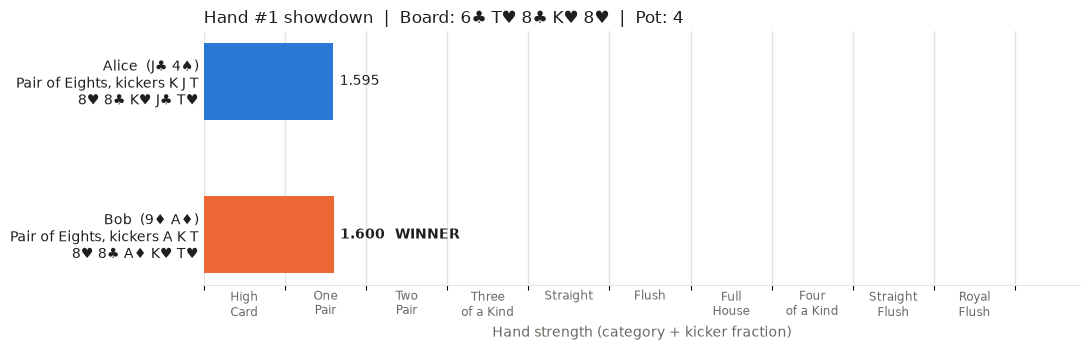

In [8]:
# Cell 8: Horizontal Showdown Comparison Bar Chart
SEAT_COLORS = ["#2a78d6", "#eb6834"]  # seat 1 blue, seat 2 orange
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3de"


def plot_showdown(record, ax=None):
    """Bar length = hand strength (category + kicker fraction).

    Bars are colored by seat, so a player keeps the same color in every hand.
    """
    if record["hand_ranks"] is None:
        print(f"Hand #{record['hand']} ended by a fold: nothing to compare.")
        return None
    ranks = record["hand_ranks"]
    names = record["seats"]
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 3.6))

    for y, name in enumerate(names):
        rank = ranks[name]
        ax.barh(y, rank.strength, height=0.5, color=SEAT_COLORS[y], zorder=3)
        tag = ""
        if name in record["winners"]:
            tag = "  SPLIT" if len(record["winners"]) > 1 else "  WINNER"
        ax.text(
            rank.strength + 0.08,
            y,
            f"{rank.strength:.3f}{tag}",
            va="center",
            ha="left",
            fontsize=10,
            color=INK,
            fontweight="bold" if tag else "normal",
        )

    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(
        [
            f"{name}  ({format_cards(record['hole_cards'][name])})\n"
            f"{ranks[name].describe()}\n{format_cards(ranks[name].cards)}"
            for name in names
        ],
        fontsize=10,
        color=INK,
    )
    ax.invert_yaxis()

    ax.set_xlim(0, 10.8)
    # Gridlines mark category boundaries; labels sit in the middle of each band.
    ax.set_xticks(range(11))
    ax.set_xticklabels([])
    ax.set_xticks([c + 0.5 for c in HandCategory], minor=True)
    ax.set_xticklabels(
        [c.label.replace(" ", "\n", 1) for c in HandCategory],
        minor=True,
        fontsize=8.5,
        color=MUTED,
    )
    ax.tick_params(axis="x", which="minor", length=0)
    ax.grid(axis="x", which="major", color=GRID, linewidth=1, zorder=0)
    ax.set_xlabel("Hand strength (category + kicker fraction)", color=MUTED)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(axis="y", length=0)
    ax.set_title(
        f"Hand #{record['hand']} showdown  |  Board: "
        f"{format_cards(record['board'])}  |  Pot: {record['pot']}",
        loc="left",
        fontsize=12,
        color=INK,
    )
    plt.tight_layout()
    return ax


plot_showdown(demo_record)
plt.show()

Hands played: 500 | showdowns: 279 | folds: 221
RandomBot-1: +947 chips (+94.7 big blinds per 100 hands)
RandomBot-2: -947 chips (-94.7 big blinds per 100 hands)
Chips conserved: True
Showdown hand categories: {'One Pair': 248, 'Two Pair': 125, 'High Card': 103, 'Three of a Kind': 33, 'Straight': 20, 'Full House': 16, 'Flush': 13}


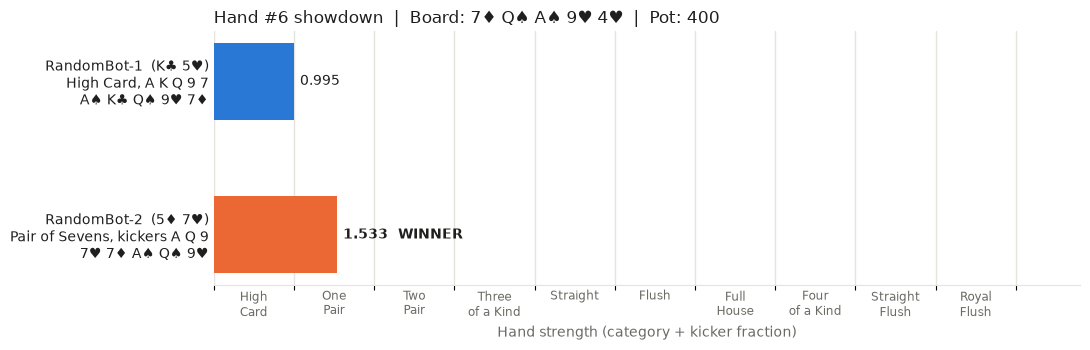

In [9]:
# Cell 9: Autonomous AI-vs-AI session (0 human players)
session = GameEngine(
    Player("RandomBot-1", 200, RandomAgent(rng=random.Random(1))),
    Player("RandomBot-2", 200, RandomAgent(rng=random.Random(2))),
    seed=2026,
    verbose=False,
)
# No-limit random bots bust each other within a few hands, so stacks are
# reset to 200 before every hand and results are tracked per hand.
history = session.play_session(max_hands=500, reset_stacks=True)

showdowns = [h for h in history if h["result"] == "showdown"]
categories = Counter(
    rank.category.label for h in showdowns for rank in h["hand_ranks"].values()
)
winnings = Counter()
for h in history:
    winnings.update(h["net"])
print(
    f"Hands played: {len(history)} | showdowns: {len(showdowns)} | "
    f"folds: {len(history) - len(showdowns)}"
)
for name, net in winnings.items():
    bb_per_100 = net / session.big_blind / len(history) * 100
    print(f"{name}: {net:+d} chips ({bb_per_100:+.1f} big blinds per 100 hands)")
print("Chips conserved:", sum(winnings.values()) == 0)
print("Showdown hand categories:", dict(categories.most_common()))

# Chart the biggest showdown pot of the session.
if showdowns:
    plot_showdown(max(showdowns, key=lambda h: h["pot"]))
    plt.show()

In [10]:
# Cell 10: Interactive table UI (1 human vs. AI)
import html

import ipywidgets as widgets
from IPython.display import display

FELT, FELT_EDGE, FELT_TEXT = "#1f5f3f", "#123d27", "#f4f1ea"
CARD_RED, CARD_BLACK = "#c8102e", "#16161a"


def action_phrase(kind, street_total):
    """'raises to 24', 'goes all-in (200)', ... for the status bar."""
    return {
        "fold": "folds",
        "check": "checks",
        "call": "calls",
        "bet": f"bets {street_total}",
        "raise": f"raises to {street_total}",
        "all-in": f"goes all-in ({street_total})",
    }[kind]


def card_html(card=None, face_down=False):
    """One playing card as inline HTML (an empty slot when card is None)."""
    box = (
        "display:inline-flex;flex-direction:column;align-items:center;"
        "justify-content:center;width:48px;height:68px;margin:0 3px;"
        "border-radius:7px;box-sizing:border-box;vertical-align:middle;"
        "font-family:system-ui,sans-serif;font-weight:700;line-height:1.05;"
    )
    if card is None:
        return f'<div style="{box}border:2px dashed rgba(255,255,255,.25);"></div>'
    if face_down:
        back = (
            "background:repeating-linear-gradient(45deg,#8c1d2c 0 5px,"
            "#a83242 5px 10px);border:3px solid #f4f1ea;"
        )
        return f'<div style="{box}{back}"></div>'
    color = CARD_RED if card.suit in "hd" else CARD_BLACK
    rank = "10" if card.rank == 10 else card.rank_char
    return (
        f'<div style="{box}background:#fdfcf8;border:1px solid #c9c6bc;'
        f'color:{color};font-size:19px;">{rank}'
        f'<span style="font-size:22px">{SUIT_SYMBOLS[card.suit]}</span></div>'
    )


class PokerTableUI:
    """A clickable heads-up table for one human seat against one bot.

    The UI drives GameEngine.hand_steps(): bot decisions are answered
    automatically, and the generator stays paused on the human's turn until
    a button is clicked. The bot's hole cards stay face down unless the hand
    reaches showdown.
    """

    def __init__(self, engine):
        self.engine = engine
        self.human = next(p for p in engine.players if p.agent.interactive)
        self.bot = next(p for p in engine.players if p is not self.human)
        self.starting_chips = {p.name: p.chips for p in engine.players}
        self.steps = None
        self.request = None  # (player, TableState) while the human must act
        self.record = None  # the finished hand's record

        def make_button(label, style):
            # Each button needs its own Layout: a shared one would hide or
            # show all buttons together.
            return widgets.Button(
                description=label,
                button_style=style,
                layout=widgets.Layout(width="150px", height="40px"),
            )

        self.fold_btn = make_button("Fold", "")
        self.passive_btn = make_button("Check", "info")
        self.aggressive_btn = make_button("Bet", "warning")
        self.all_in_btn = make_button("All-in", "danger")
        self.next_btn = make_button("Deal next hand", "success")
        self.fold_btn.on_click(lambda _: self._act("fold"))
        self.passive_btn.on_click(lambda _: self._act(self.passive_action))
        self.aggressive_btn.on_click(lambda _: self._act(self._sized_action()))
        self.all_in_btn.on_click(lambda _: self._act("all-in"))
        self.next_btn.on_click(lambda _: self._next_hand())
        self.passive_action = self.aggressive_action = None

        # No-limit sizing: a slider for the raise-to amount plus quick presets.
        self.size_slider = widgets.IntSlider(
            description="Raise to",
            continuous_update=True,
            layout=widgets.Layout(width="330px"),
        )
        self.size_slider.observe(lambda _: self._label_aggressive(), names="value")
        presets = []
        for label, fraction in (
            ("Min", None),
            ("½ Pot", 0.5),
            ("¾ Pot", 0.75),
            ("Pot", 1.0),
        ):
            preset = widgets.Button(
                description=label, layout=widgets.Layout(width="64px")
            )
            preset.on_click(lambda _, f=fraction: self._preset(f))
            presets.append(preset)
        self.sizing_row = widgets.HBox(
            [self.size_slider, *presets], layout=widgets.Layout(gap="6px")
        )

        self.table = widgets.HTML()
        self.log_box = widgets.HTML()
        self.chart_out = widgets.Output()
        controls = widgets.HBox(
            [
                self.fold_btn,
                self.passive_btn,
                self.aggressive_btn,
                self.all_in_btn,
                self.next_btn,
            ],
            layout=widgets.Layout(gap="8px", margin="8px 0 4px"),
        )
        self.root = widgets.VBox(
            [self.table, controls, self.sizing_row, self.log_box, self.chart_out]
        )

    # ----- game flow -------------------------------------------------------
    def show(self):
        display(self.root)
        self._next_hand()

    def _next_hand(self):
        with self.chart_out:
            self.chart_out.clear_output()
            if any(p.chips == 0 for p in self.engine.players):
                self._new_game()
            self.record = None
            self.steps = self.engine.hand_steps()
            self._advance(None)

    def _new_game(self):
        for player in self.engine.players:
            player.chips = self.starting_chips[player.name]
        self.engine.hand_number = 0
        self.engine.history = []

    def _act(self, action):
        if self.request is None or action is None:
            return
        with self.chart_out:
            self._advance(action)

    def _sized_action(self):
        if self.aggressive_action is None:
            return None
        return self.aggressive_action, self.size_slider.value

    def _preset(self, fraction):
        if self.request is None:
            return
        _, state = self.request
        self.size_slider.value = (
            state.min_raise_to
            if fraction is None
            else state.raise_to_for_pot_fraction(fraction)
        )

    def _advance(self, action):
        """Send an action, then let the bot play until it's our turn."""
        try:
            player, state = self.steps.send(action)
            while not player.agent.interactive:
                player, state = self.steps.send(player.agent.decide(state))
            self.request = (player, state)
        except StopIteration as finished:
            self.request = None
            self.record = finished.value
        self._render()
        if self.record and self.record["result"] == "showdown":
            plot_showdown(self.record)
            plt.show()

    # ----- rendering -------------------------------------------------------
    def _render(self):
        self.table.value = self._table_html()
        self.log_box.value = self._log_html()
        self._update_buttons()

    def _seat_html(self, player, reveal):
        if self.record:
            on_button = self.record["button"] == player.name
        else:
            on_button = self.engine.players[self.engine.button] is player
        dealer = (
            ' <span style="background:#f4f1ea;color:#16161a;border-radius:50%;'
            'padding:1px 6px;font-size:11px;font-weight:700">D</span>'
            if on_button
            else ""
        )
        cards = player.hole_cards or [None, None]
        hidden = not reveal and bool(player.hole_cards)
        cards_html = "".join(card_html(c, face_down=hidden) for c in cards)
        bet = (
            f'<span style="opacity:.8">bet {player.street_bet}</span>'
            if player.street_bet and not self.record
            else ""
        )
        folded = ' <span style="opacity:.7">(folded)</span>' if player.folded else ""
        return (
            f'<div style="display:flex;align-items:center;gap:14px;">'
            f'<div>{cards_html}</div><div style="line-height:1.5">'
            f"<b>{html.escape(player.name)}</b>{dealer}{folded}<br>"
            f"{player.chips} chips &nbsp;{bet}</div></div>"
        )

    def _table_html(self):
        showdown = bool(self.record) and self.record["result"] == "showdown"
        board = list(self.engine.board) + [None] * (5 - len(self.engine.board))
        pot = self.record["pot"] if self.record else self.engine.pot
        street = "Hand over" if self.record else self.engine.street
        # Chips already in the pot this hand still count as ours until it ends.
        net = (
            self.human.chips
            + self.human.total_bet
            - self.starting_chips[self.human.name]
        )
        return (
            f'<div style="background:{FELT};border:6px solid {FELT_EDGE};'
            f"border-radius:18px;padding:16px 20px;color:{FELT_TEXT};"
            f'font-family:system-ui,sans-serif;font-size:14px;max-width:640px;">'
            f'<div style="display:flex;justify-content:space-between;opacity:.85;'
            f'font-size:12px;"><span>Hand #{self.engine.hand_number} &middot; '
            f"{street}</span><span>Blinds {self.engine.small_blind}/"
            f"{self.engine.big_blind} &middot; Session {net:+d}</span></div>"
            f'<div style="margin:12px 0">{self._seat_html(self.bot, showdown)}</div>'
            f'<div style="text-align:center;margin:18px 0">'
            f"{''.join(card_html(c) for c in board)}"
            f'<div style="margin-top:8px;font-size:16px"><b>Pot: {pot}</b></div></div>'
            f'<div style="margin:12px 0">{self._seat_html(self.human, True)}</div>'
            f'<div style="margin-top:10px;padding:8px 12px;border-radius:8px;'
            f'background:rgba(0,0,0,.28);font-size:15px">{self._status()}</div>'
            f"</div>"
        )

    def _status(self):
        if self.request:
            _, state = self.request
            last = next(
                (a for a in reversed(self.engine.action_log) if a[1] == self.bot.name),
                None,
            )
            prefix = (
                f"{html.escape(self.bot.name)} {action_phrase(last[2], last[3])}. "
                if last and last[0] == state.street
                else ""
            )
            if state.to_call:
                return f"{prefix}<b>Your turn</b>: {min(state.to_call, state.chips)} to call."
            return f"{prefix}<b>Your turn</b>: check or bet."
        record = self.record
        if record["result"] == "fold":
            winner = record["winners"][0]
            loser = self.bot.name if winner == self.human.name else self.human.name
            return f"{html.escape(loser)} folded. <b>{html.escape(winner)} wins {record['pot']}.</b>"
        ranks = record["hand_ranks"]
        lines = [
            f"{html.escape(name)}: {rank.describe()}" for name, rank in ranks.items()
        ]
        if len(record["winners"]) > 1:
            outcome = f"<b>Split pot of {record['pot']}.</b>"
        else:
            outcome = (
                f"<b>{html.escape(record['winners'][0])} wins {record['pot']}.</b>"
            )
        if any(p.chips == 0 for p in self.engine.players):
            outcome += " Game over!"
        return "<br>".join(lines + [outcome])

    def _log_html(self):
        lines = [
            html.escape(msg.strip())
            for owner, msg in self.engine.hand_log
            if self.engine.can_see(owner) and msg.strip()
        ]
        return (
            '<div style="font-family:Consolas,monospace;font-size:12px;'
            "color:#3d3c38;background:#f4f2ec;border-radius:8px;"
            'padding:8px 12px;max-width:616px;line-height:1.45;">'
            + "<br>".join(lines[-14:])
            + "</div>"
        )

    @staticmethod
    def _show(widget, visible):
        widget.layout.display = None if visible else "none"

    def _update_buttons(self):
        in_hand = self.request is not None
        no_limit = self.engine.betting == "no-limit"
        for btn in (self.fold_btn, self.passive_btn, self.aggressive_btn):
            self._show(btn, in_hand)
        self._show(self.all_in_btn, in_hand and no_limit)
        self._show(self.next_btn, not in_hand)
        if not in_hand:
            self._show(self.sizing_row, False)
            game_over = any(p.chips == 0 for p in self.engine.players)
            self.next_btn.description = "New game" if game_over else "Deal next hand"
            return

        player, state = self.request
        legal = state.legal_actions
        self.fold_btn.disabled = "fold" not in legal
        if "check" in legal:
            self.passive_action, self.passive_btn.description = "check", "Check"
        else:
            amount = min(state.to_call, player.chips)
            self.passive_action, self.passive_btn.description = "call", f"Call {amount}"

        self.aggressive_action = next((a for a in ("bet", "raise") if a in legal), None)
        self.aggressive_btn.disabled = self.aggressive_action is None
        self.all_in_btn.disabled = "all-in" not in legal
        self.all_in_btn.description = f"All-in ({player.chips})"
        self._show(self.sizing_row, no_limit and self.aggressive_action is not None)
        if self.aggressive_action is not None:
            # Reset the range in an order the slider always accepts (min <= max).
            self.size_slider.min = 0
            self.size_slider.max = state.max_raise_to
            self.size_slider.min = state.min_raise_to
            self.size_slider.value = state.min_raise_to
        self._label_aggressive()

    def _label_aggressive(self):
        if self.request is None:
            return
        _, state = self.request
        if self.aggressive_action is None:
            self.aggressive_btn.description = "Raise"
            return
        amount = (
            self.size_slider.value
            if self.engine.betting == "no-limit"
            else state.min_raise_to
        )
        verb = "Bet" if self.aggressive_action == "bet" else "Raise to"
        suffix = " (all-in)" if amount == state.max_raise_to else ""
        self.aggressive_btn.description = f"{verb} {amount}{suffix}"

In [ ]:
# Cell 11: Play! (1 human vs. AI). Re-run this cell to start a fresh match.
human_game = GameEngine(
    Player("Hero", 200, HumanAgent()),  # you
    Player("Bot", 200, RandomAgent()),
    verbose=False,
)
PokerTableUI(human_game).show()